# Exact SageMath verification of the \(51\)-line simplicial arrangement

**Companion to “A sporadic simplicial arrangement of 51 lines” — Tomás S. R. Silva.**

This notebook follows the paper's construction, incidence certificate, theorem, and geometric explanation. It implements the computations directly in SageMath: it does **not** import either Python verifier in this repository. The stored JSON certificate is compared only after the construction has been verified independently.

**Run:** select a **SageMath** kernel and use **Restart Kernel and Run All Cells**. The notebook was executed with SageMath 10.8 and its **PyNormaliz** backend. PyNormaliz is required for the exact enumeration of all chambers; Sage's feature check below provides installation guidance if it is unavailable. Ordinary execution writes no files.

We use the documented [`HyperplaneArrangements`](https://doc.sagemath.org/html/en/reference/discrete_geometry/sage/geometry/hyperplane_arrangement/arrangement.html) interface over a real-embedded number field, including `intersection_poset`, `characteristic_polynomial`, `n_regions`, `face_vector`, `matroid`, `regions`, and `is_simplicial`.

**Convention.** Sage represents the central planes in \(K^3\). Their projectivizations are the paper's lines in \(\mathbb P^2(\mathbb R)\). Thus **1,440 central chambers correspond to 720 projective chambers**. All proof computations are exact; numerical approximations are used only in the final illustration.

In [1]:
from sage.all import *
from sage.env import SAGE_VERSION
from sage.features.normaliz import PyNormaliz
from collections import Counter, deque
from itertools import combinations, product
from pathlib import Path
import json
from IPython.display import display, Markdown

PyNormaliz().require()
checks = []

def check(condition, message):
    '''A mathematical check that remains active under Python optimization.'''
    if not bool(condition):
        raise AssertionError(message)
    checks.append(message)

print("SageMath", SAGE_VERSION)
print("Exact chamber backend: Normaliz")

SageMath 10.8
Exact chamber backend: Normaliz


## 1. The field and the real embedding

Put \(\varphi=(1+\sqrt5)/2\) and \(s=\sqrt{\varphi}>0\). We work in
\[
K=\mathbb Q[s]/(s^4-s^2-1),\qquad \varphi=s^2,\qquad \varphi^{-1}=\varphi-1.
\]
`AA` is Sage's **exact real algebraic field**, so the embedding below selects the positive root without a floating-point tolerance. We separately check irreducibility over \(\mathbb Q\). A field element has the unique form \(a_0+a_1s+a_2s^2+a_3s^3\).

In [2]:
u = polygen(QQ, "u")
defining_polynomial = u**4 - u**2 - 1
check(defining_polynomial.is_irreducible(), "the defining quartic is irreducible")
positive_root = ((AA(1) + AA(5).sqrt()) / 2).sqrt()
K = NumberField(defining_polynomial, "s", embedding=positive_root)
s = K.gen()
phi = s**2
phiinv = 1 / phi

check(s**4 == s**2 + 1, "quartic defining relation")
check(phi**2 == phi + 1 and phiinv == phi - 1, "golden-ratio identities")
check(AA(s) == positive_root and QQ(5)/4 < AA(s) < QQ(13)/10,
      "the chosen embedding is the positive real root")

def coefficients(a):
    c = list(K(a))
    return tuple(c + [QQ(0)] * (4 - len(c)))

def coordinate_key(v):
    '''Sort by rational coefficients, not by floating-point values.'''
    return tuple(c for a in v for c in coefficients(a))

def projective(v):
    v = tuple(K(a) for a in v)
    first = next((a for a in v if a != 0), None)
    if first is None:
        raise ValueError("The zero vector has no projective representative.")
    return tuple(a / first for a in v)

def scalar_product(a, b):
    return vector(K, a).dot_product(vector(K, b))

def projective_cross(a, b):
    return projective(vector(K, a).cross_product(vector(K, b)))

print(K)
print("Basis: 1, s, s^2, s^3; phi = s^2")

Number Field in s with defining polynomial u^4 - u^2 - 1 with s = 1.272019649514069?
Basis: 1, s, s^2, s^3; phi = s^2


## 2. The icosahedral rotation group

We use the three matrices displayed in Section 2. Their powers, determinants, orthogonality, and action on the twelve actual vertices are checked before enumerating the generated group. The permutation action on those vertices also identifies the group with \(A_5\).

In [3]:
kappa = matrix(K, [[0,0,1], [1,0,0], [0,1,0]])
eta = diagonal_matrix(K, [1,-1,-1])
rho = matrix(K, [[1,-phi,phiinv], [phi,phiinv,-1], [phiinv,1,phi]]) / 2
generators = (kappa, eta, rho)
identity = identity_matrix(K, 3)

vertices = set()
for epsilon, epsilon_prime in product((-1, 1), repeat=2):
    v = (K(0), epsilon*phi, K(epsilon_prime))
    vertices.update(v[j:] + v[:j] for j in range(3))
check(len(vertices) == 12, "twelve distinct icosahedral vertices")

for name, g, order in zip(("kappa", "eta", "rho"), generators, (3,2,5)):
    check(g.transpose()*g == identity and g.det() == 1,
          name + " is an orientation-preserving orthogonal matrix")
    check(g**order == identity and all(g**j != identity for j in range(1, order)),
          name + " has the stated exact order")
    check({tuple(g*vector(K,v)) for v in vertices} == vertices,
          name + " preserves the vertex set")

found = {tuple(identity.list()): identity}
pending = deque([identity])
while pending:
    current = pending.popleft()
    for generator in generators:
        new = generator*current
        key = tuple(new.list())
        if key not in found:
            found[key] = new
            pending.append(new)
    check(len(found) <= 60, "group enumeration has not exceeded order 60")
rotations = list(found.values())
check(len(rotations) == 60, "the generated group has order 60")
check(all({tuple(g*vector(K,v)) for v in vertices} == vertices for g in rotations),
      "all sixty rotations preserve the twelve vertices")

vertex_list = sorted(vertices, key=coordinate_key)
vertex_index = {v: j+1 for j,v in enumerate(vertex_list)}
def vertex_permutation(g):
    return Permutation([vertex_index[tuple(g*vector(K,v))] for v in vertex_list])

permutation_group = PermutationGroup([vertex_permutation(g) for g in generators])
check(permutation_group.order() == 60, "the vertex action is faithful")
check(permutation_group.is_isomorphic(AlternatingGroup(5)), "I is isomorphic to A5")

def orbit(v):
    return {projective(g*vector(K,v)) for g in rotations}

print("Generator orders: 3, 2, 5")
print("Rotation group: 60 elements, isomorphic to A5")

Generator orders: 3, 2, 5
Rotation group: 60 elements, isomorphic to A5


## 3. The three line orbits and the closed formulas

A normal \([a:b:c]\) represents \(ax+by+cz=0\). We first generate the three orbits from their seed normals, then independently generate the coordinate formulas (1)–(3). In the last formula, the **same** sign \(\delta\) occurs in both nonconstant coordinates.

In [4]:
O15 = sorted(orbit((1,0,0)), key=coordinate_key)
O6 = sorted(orbit((0,phi,1)), key=coordinate_key)
O30 = sorted(orbit((0,1,s)), key=coordinate_key)
line_orbits = (O15, O6, O30)
orbit_names = ("O15", "O6", "O30")
lines = O15 + O6 + O30
check(tuple(map(len, line_orbits)) == (15,6,30), "line orbit sizes are 15, 6, 30")
check(len(lines) == len(set(lines)) == 51, "all three line orbits are disjoint")

def cyclic(v):
    v = tuple(v)
    return {projective(v[j:] + v[:j]) for j in range(3)}

formula15 = cyclic((1,0,0))
for epsilon, epsilon_prime in product((-1,1), repeat=2):
    formula15.update(cyclic((1, epsilon*phi, epsilon_prime*phiinv)))
formula6 = set()
formula30 = set()
for epsilon in (-1,1):
    formula6.update(cyclic((0,phi,epsilon)))
    formula30.update(cyclic((0,1,epsilon*s)))
for epsilon, epsilon_prime, delta in product((-1,1), repeat=3):
    formula30.update(cyclic((1, epsilon*(1+delta*s),
                            epsilon_prime*(1+delta*phiinv*s))))
check((formula15, formula6, formula30) == tuple(set(o) for o in line_orbits),
      "the closed formulas equal all three group orbits")
print("Closed formulas and rotation orbits agree: 15 + 6 + 30 = 51 lines")

Closed formulas and rotation orbits agree: 15 + 6 + 30 = 51 lines


### Mirrors and polar lines

For a nonzero normal \(v\), reflection in its perpendicular plane has matrix
\[
R_v=\operatorname{Id}-2\,\frac{vv^{\mathsf T}}{v^{\mathsf T}v}.
\]
The full icosahedral symmetry group is \(\{\pm g:g\in I\}\), conventionally called the reflection group of type \(H_3\). We check that its fifteen plane reflections have exactly the mirrors in \(\mathcal O_{15}\). We also verify that \(\mathcal O_6\) is the set of polar lines to the six axes of order-five rotations.

In [5]:
full_group = rotations + [-g for g in rotations]
full_keys = {tuple(g.list()) for g in full_group}
check(len(full_keys) == 120, "the full icosahedral symmetry group has order 120")
reflections = []
for v in O15:
    column = vector(K,v).column()
    r = identity - 2*column*column.transpose()/scalar_product(v,v)
    check(tuple(r.list()) in full_keys, "each O15 normal defines an icosahedral symmetry")
    check(r.det() == -1 and (r-identity).rank() == 1 and r**2 == identity,
          "each O15 symmetry is a plane reflection")
    reflections.append(r)
all_reflection_keys = {tuple(g.list()) for g in full_group
                       if g.det() == -1 and (g-identity).rank() == 1}
check({tuple(g.list()) for g in reflections} == all_reflection_keys,
      "O15 gives all fifteen mirrors")
reflection_group = PermutationGroup([vertex_permutation(g) for g in reflections])
check(reflection_group.order() == 120, "the mirrors generate the full reflection group")

order_five = [g for g in rotations if g != identity and g**5 == identity]
fivefold_axes = {projective((g-identity).right_kernel().basis()[0]) for g in order_five}
check(len(order_five) == 24 and len(fivefold_axes) == 6,
      "there are six fivefold rotation axes")
check(fivefold_axes == set(O6) == {projective(v) for v in vertices},
      "O6 consists of the polars to the fivefold axes")
print("H3: fifteen mirrors; O6: six polar lines to the fivefold axes")

H3: fifteen mirrors; O6: six polar lines to the fivefold axes


## 4. Sage's hyperplane-arrangement objects

The following is the number-field construction described in the [Sage reference manual](https://doc.sagemath.org/html/en/reference/discrete_geometry/sage/geometry/hyperplane_arrangement/arrangement.html). Each pair `[normal, 0]` specifies a central plane. Normaliz retains exact arithmetic over the embedded number field and makes full chamber enumeration practical.

In [6]:
H = HyperplaneArrangements(K, names=("x", "y", "z"))
x, y, z = H.gens()

def arrangement_from_normals(normals):
    return H([[list(v), K(0)] for v in normals], backend="normaliz")

A51 = arrangement_from_normals(lines)
B = arrangement_from_normals(O15 + O6)
check(len(A51) == 51 and len(B) == 21, "Sage sees 51 and 21 distinct planes")
check(A51.is_central() and A51.is_linear() and A51.is_essential(),
      "A51 is central, linear, and essential")
check(A51.dimension() == A51.rank() == 3, "ambient dimension and rank are three")
print(A51)
print(B)

Arrangement of 51 hyperplanes of dimension 3 and rank 3
Arrangement of 21 hyperplanes of dimension 3 and rank 3


## 5. Enumerate every intersection independently of Table 1

Intersect every pair of normals by a cross product, identify proportional triples, and then test every resulting point against **every** line by an exact dot product. This prevents the expected table or multiplicities from being used as input to the lattice computation.

In [7]:
incidences = {}
for i,j in combinations(range(len(lines)), 2):
    point = projective_cross(lines[i], lines[j])
    incidences.setdefault(point, set()).update((i,j))
for point, incident in incidences.items():
    direct = {i for i,normal in enumerate(lines) if scalar_product(point,normal) == 0}
    check(direct == incident, "pair enumeration agrees with direct incidence tests")

t_counts = Counter(len(incident) for incident in incidences.values())
vertices_per_line = [sum(i in incident for incident in incidences.values())
                     for i in range(len(lines))]
pair_count = sum(binomial(r,2)*count for r,count in t_counts.items())
check(pair_count == binomial(51,2) == 1275, "all unordered line pairs are accounted for")
check(dict(t_counts) == {2:120, 3:190, 5:36, 6:15}, "the paper's intersection numbers")
check(len(incidences) == 361, "there are 361 projective intersection points")
check(vertices_per_line[:21] == [20]*21 and vertices_per_line[21:] == [22]*30,
      "original lines have 20 vertices and added lines have 22")
print("Line pairs:", pair_count)
print("Line/point dot-product tests:", len(lines)*len(incidences))
print("t-vector:", dict(sorted(t_counts.items())))
print("Vertices per line:", dict(sorted(Counter(vertices_per_line).items())))

Line pairs: 1275
Line/point dot-product tests: 18411
t-vector: {2: 120, 3: 190, 5: 36, 6: 15}
Vertices per line: {20: 21, 22: 30}


## 6. Reproduce every row of Table 1

Each profile counts incident lines from \((\mathcal O_{15},\mathcal O_6,\mathcal O_{30})\). We verify every point in each group orbit, not only the displayed representative. The disjoint orbits must exhaust the previously computed intersection set.

In [8]:
point_specs = [
    ((0,0,1),                       15, (2,2,2)),
    ((0,1,phiinv),                   6, (5,0,0)),
    ((0,1,-s),                      30, (1,0,4)),
    ((0,1,-1+phiinv*s),             30, (1,0,2)),
    ((0,1,-1-phi),                  10, (3,0,0)),
    ((0,1,-1-phiinv*s),             30, (1,0,2)),
    ((0,1,-phi-phi*s),              30, (1,0,2)),
    ((0,1,-phi+phi*s),              30, (1,0,2)),
    ((phi,s,-1),                    60, (0,1,2)),
    ((0,1,phiinv*s),                30, (1,0,1)),
    ((0,1,-phi),                    30, (1,1,0)),
    ((1,-s**3,s**3),                60, (0,0,2)),
]
representative_labels = [
    r"(0:0:1)", r"(0:1:\varphi^{-1})", r"(0:1:-s)",
    r"(0:1:-1+\varphi^{-1}s)", r"(0:1:-1-\varphi)",
    r"(0:1:-1-\varphi^{-1}s)", r"(0:1:-\varphi-\varphi s)",
    r"(0:1:-\varphi+\varphi s)", r"(\varphi:s:-1)",
    r"(0:1:\varphi^{-1}s)", r"(0:1:-\varphi)", r"(1:-s^3:s^3)",
]
line_type = [0]*15 + [1]*6 + [2]*30
covered = set()
point_orbits = []
table_rows = ["| Representative | Orbit size | Multiplicity | Profile |",
              "|---|---:|---:|---|"]
for label, (representative, size, profile) in zip(representative_labels, point_specs):
    points = orbit(representative)
    check(len(points) == size, "point-orbit size")
    check(not covered.intersection(points), "point orbits are pairwise disjoint")
    for point in points:
        check(point in incidences, "every displayed orbit point is an intersection")
        actual = tuple(sum(line_type[i] == j for i in incidences[point]) for j in range(3))
        check(actual == profile, "the profile of every point in its orbit")
    covered.update(points)
    point_orbits.append(points)
    table_rows.append("| $" + label + "$ | " + str(size) + " | " +
                      str(sum(profile)) + " | " + str(profile) + " |")
check(covered == set(incidences), "the twelve orbits exhaust all intersections")
display(Markdown("\n".join(table_rows)))
print("All twelve rows verified; total points:", sum(size for _,size,_ in point_specs))

| Representative | Orbit size | Multiplicity | Profile |
|---|---:|---:|---|
| $(0:0:1)$ | 15 | 6 | (2, 2, 2) |
| $(0:1:\varphi^{-1})$ | 6 | 5 | (5, 0, 0) |
| $(0:1:-s)$ | 30 | 5 | (1, 0, 4) |
| $(0:1:-1+\varphi^{-1}s)$ | 30 | 3 | (1, 0, 2) |
| $(0:1:-1-\varphi)$ | 10 | 3 | (3, 0, 0) |
| $(0:1:-1-\varphi^{-1}s)$ | 30 | 3 | (1, 0, 2) |
| $(0:1:-\varphi-\varphi s)$ | 30 | 3 | (1, 0, 2) |
| $(0:1:-\varphi+\varphi s)$ | 30 | 3 | (1, 0, 2) |
| $(\varphi:s:-1)$ | 60 | 3 | (0, 1, 2) |
| $(0:1:\varphi^{-1}s)$ | 30 | 2 | (1, 0, 1) |
| $(0:1:-\varphi)$ | 30 | 2 | (1, 1, 0) |
| $(1:-s^3:s^3)$ | 60 | 2 | (0, 0, 2) |

All twelve rows verified; total points: 361


In [9]:
# The two examples singled out in the proof of Proposition 3.1.
example_six_lines = {
    projective(v) for v in [(1,0,0), (0,1,0), (phi,1,0), (phi,-1,0),
                            (1,s,0), (1,-s,0)]
}
example_three_lines = {
    projective(v) for v in [(1,0,phi), (0,1,s), (1,-s,0)]
}
def actual_incident_normals(point):
    return {lines[i] for i in incidences[projective(point)]}

check(actual_incident_normals((0,0,1)) == example_six_lines,
      "exactly the six stated lines pass through (0:0:1)")
check(actual_incident_normals((phi,s,-1)) == example_three_lines,
      "exactly the three stated lines pass through (phi:s:-1)")
print("Both explicit incidence examples in the proof are verified.")

Both explicit incidence examples in the proof are verified.


## 7. Independent checks with Sage's intersection lattice

`intersection_poset(element_label="subset")` records each flat by the indices of the hyperplanes containing it. Sage sorts its hyperplanes, so we first translate its indices into our line order. We compare the **entire set of rank-two flats**, not just their number.

In [10]:
lattice = A51.intersection_poset(element_label="subset")
levels = lattice.level_sets()
check([len(level) for level in levels] == [1,51,361,1],
      "Sage's lattice has the expected rank levels")
line_index = {normal:i for i,normal in enumerate(lines)}
sage_to_ours = [line_index[projective(h.normal())] for h in A51.hyperplanes()]
native_flats = {frozenset(sage_to_ours[int(j)] for j in flat) for flat in levels[2]}
check(native_flats == {frozenset(incident) for incident in incidences.values()},
      "Sage's entire rank-two lattice equals the independently computed incidence lattice")
check(Counter(len(flat) for flat in levels[2]) == t_counts,
      "Sage's lattice reproduces the t-vector")
print("Intersection-lattice levels:", [len(level) for level in levels])
print("All 361 rank-two flats agree exactly.")

Intersection-lattice levels: [1, 51, 361, 1]
All 361 rank-two flats agree exactly.


## 8. Simpliciality and the face counts

For the essential projective arrangement,
\[
f_0=\sum t_r,\quad f_1=\sum r t_r,\quad f_2=1-f_0+f_1.
\]
The equality \(3f_2=2f_1\), equivalently zero Melchior defect, says that every projective chamber is triangular. We then use Sage and Normaliz to **enumerate all central chambers** and check their facets and rays directly.

In [11]:
f0 = sum(t_counts.values())
f1 = sum(r*count for r,count in t_counts.items())
f2 = 1-f0+f1
melchior_defect = t_counts[2] - 3 - sum((r-3)*count for r,count in t_counts.items() if r >= 4)
check((f0,f1,f2) == (361,1080,720), "projective f-vector")
check(melchior_defect == 0 and 3*f2 == 2*f1, "Melchior equality proves simpliciality")

check(A51.is_simplicial(), "Sage's native simpliciality test")
chambers = A51.regions()
check(len(chambers) == 1440, "there are 1440 central chambers")
chamber_types = Counter((C.dim(), C.n_facets(), C.n_rays(), C.n_lines()) for C in chambers)
check(chamber_types == {(3,3,3,0):1440},
      "every central chamber is a pointed three-dimensional simplicial cone")
native_face_vector = tuple(A51.face_vector())
check(native_face_vector == (1,2*f0,2*f1,2*f2),
      "Sage's central face vector agrees with the projective face vector")
print("Melchior defect:", melchior_defect)
print("Projective f-vector:", (f0,f1,f2))
print("Central face vector (including the origin):", native_face_vector)
print("Chamber types (dimension, facets, rays, lineality):", dict(chamber_types))

Melchior defect: 0
Projective f-vector: (361, 1080, 720)
Central face vector (including the origin): (1, 722, 2160, 1440)
Chamber types (dimension, facets, rays, lineality): {(3, 3, 3, 0): 1440}


## 9. Characteristic polynomial and the remaining conclusions

The coefficient \(b_2=\sum(r-1)t_r\) is computed directly. Sage computes the characteristic polynomial independently using its arrangement methods. A negative discriminant for the quadratic factor rules out supersolvability, because supersolvable arrangements have integer linear factors.

Irreducibility is checked both by the rank-three near-pencil criterion and by connectivity of Sage's normal matroid. For an additional direct lattice check, a projective intersection point is modular precisely when the line joining it to every other intersection point belongs to the arrangement. There are no such points here.

In [12]:
Rchi = PolynomialRing(QQ, "T")
T = Rchi.gen()
b2 = sum((r-1)*count for r,count in t_counts.items())
chi_from_incidence = T**3 - 51*T**2 + b2*T + (51-1-b2)
chi_native = Rchi(A51.characteristic_polynomial())
check(b2 == 719, "the coefficient b2 is 719")
check(chi_native == chi_from_incidence == (T-1)*(T**2-50*T+669),
      "Sage and the incidence formula give the same characteristic polynomial")
quadratic = T**2-50*T+669
check(quadratic.discriminant() == -176 and quadratic.is_irreducible(),
      "the quadratic factor is irreducible and has discriminant -176")
check(A51.n_regions() == -chi_native(-1) == 1440,
      "Sage's region count agrees with Zaslavsky's formula and chamber enumeration")

check(max(t_counts) == 6 < 50, "the essential rank-three arrangement is not a near-pencil")
check(A51.matroid().is_connected(), "the normal matroid is connected: A51 is irreducible")
line_set = set(lines)
modular_points = [
    p for p in incidences
    if all(projective_cross(p,q) in line_set for q in incidences if q != p)
]
check(modular_points == [], "there is no modular intersection point")
check(len(lines) > 37 and len(lines) % 2 == 1 and len(lines) % 4 == 3,
      "51 exceeds 37 and belongs to neither allowed infinite-family line count")
print("Characteristic polynomial:", chi_native.factor())
print("Quadratic discriminant:", quadratic.discriminant())
print("Irreducible: True; modular intersection points: 0; supersolvable: False")
print("Sporadic: near-pencils, the 2n family, and the 4m+1 family are excluded.")

Characteristic polynomial: (T - 1) * (T^2 - 50*T + 669)
Quadratic discriminant: -176
Irreducible: True; modular intersection points: 0; supersolvable: False
Sporadic: near-pencils, the 2n family, and the 4m+1 family are excluded.


## 10. The 21-line starting arrangement

Before the new orbit is added, the two old orbits already form a simplicial arrangement. This calculation uses only those 21 normals. A later cell proves the catalogue identification by an explicit projective change of coordinates.

In [13]:
base_lines = O15 + O6
base_incidences = {}
for i,j in combinations(range(21),2):
    point = projective_cross(base_lines[i], base_lines[j])
    base_incidences.setdefault(point,set()).update((i,j))
for point,incident in base_incidences.items():
    check(incident == {i for i,n in enumerate(base_lines) if scalar_product(point,n) == 0},
          "base arrangement incidences")
base_t = Counter(len(incident) for incident in base_incidences.values())
check(base_t == {2:30,3:10,4:15,5:6}, "B has the stated classical intersection counts")
base_defect = base_t[2]-3-sum((r-3)*count for r,count in base_t.items() if r>=4)
check(base_defect == 0 and B.is_simplicial(), "B is simplicial")
check(B.n_regions() == 240, "B has 240 central, hence 120 projective, chambers")
print("B: 21 lines; t-vector", dict(sorted(base_t.items())))
print("Melchior defect:", base_defect, "; projective chambers:", B.n_regions()//2)

B: 21 lines; t-vector {2: 30, 3: 10, 4: 15, 5: 6}
Melchior defect: 0 ; projective chambers: 120


## 11. Why the parameter \(\sqrt{\varphi}\) appears

The pencil through \(P=(1:0:0)\) is \(\ell_t=[0:1:t]\), including
\(\ell_\infty=[0:0:1]\). We now reproduce Section 4 as polynomial
identities in \(K[t]\), so no numerical approximations or sampling are
used to establish the moving-line formulas.

The rotations \(g_1,g_2\) below give four moving lines
\(g_i\ell_t,\eta g_i\ell_t\). Their displayed normals differ from the
matrix products only by nonzero constant factors.

In [14]:
P = vector(K, (1, 0, 0))
base_normals = O15 + O6
check(sum(vector(K, n).dot_product(P) == 0 for n in base_normals) == 4,
      "P is a fourfold point of B")
check(eta * P == P, "P lies on the half-turn axis of eta")

g1 = matrix(K, [[phiinv, 1, phi], [-1, phi, -phiinv],
               [-phi, -phiinv, 1]]) / 2
g2 = matrix(K, [[phiinv, -1, phi], [1, phi, phiinv],
               [-phi, phiinv, 1]]) / 2
check(g1 in rotations and g2 in rotations, "g1 and g2 belong to I")

Kt = PolynomialRing(K, "t")
t = Kt.gen()
ell = vector(Kt, (0, 1, t))
L1plus = vector(Kt, (phi*t + 1, phi - t*phiinv, t - phiinv))
L1minus = vector(Kt, (-phi*t - 1, phi - t*phiinv, t - phiinv))
L2plus = vector(Kt, (phi*t - 1, phi + t*phiinv, t + phiinv))
L2minus = vector(Kt, (-phi*t + 1, phi + t*phiinv, t + phiinv))
check(2 * g1.change_ring(Kt) * ell == L1plus, "normal of g1 ell_t")
check(-2 * (eta*g1).change_ring(Kt) * ell == L1minus,
      "normal of eta g1 ell_t")
check(2 * g2.change_ring(Kt) * ell == L2plus, "normal of g2 ell_t")
check(-2 * (eta*g2).change_ring(Kt) * ell == L2minus,
      "normal of eta g2 ell_t")
print("The four moving-line formulas hold identically in K[t].")

The four moving-line formulas hold identically in K[t].


### Two simultaneous concurrences

Each pair \(L_i^+,L_i^-\) meets the mirror \(x=0\) at \(Q_i(t)\).
The determinant comparing \(Q_1(t)\) and \(Q_2(t)\) is
\(2-2t^2/\varphi\). Hence they coincide precisely at the two real
parameters \(t=\pm s\). We check that the four added lines are distinct
at both parameters and verify the complete profiles \((1,0,4)\).

Independently, \(\ell_t\) and \(\eta\kappa^{-1}\ell_t\) meet at
\((t^2:t:-1)\). This point belongs to the polar line
\([1:0:\varphi]\) exactly when \(t^2=\varphi\). Its profile is
\((0,1,2)\). A profile counts incident lines from
\(\mathcal O_{15},\mathcal O_6,\mathcal O_{30}\), in that order.

In [15]:
Q1 = vector(Kt, (0, t - phiinv, t*phiinv - phi))
Q2 = vector(Kt, (0, t + phiinv, -t*phiinv - phi))
for normal in (L1plus, L1minus):
    check(normal.dot_product(Q1) == 0, "Q1 belongs to both first lines")
for normal in (L2plus, L2minus):
    check(normal.dot_product(Q2) == 0, "Q2 belongs to both second lines")
concurrence = Q1[1]*Q2[2] - Q1[2]*Q2[1]
check(concurrence == 2 - 2*t**2/phi, "mirror concurrence polynomial")

second_normal = vector(Kt, (1, -t, 0))
check((eta*kappa.inverse()).change_ring(Kt) * ell == second_normal,
      "normal of eta kappa^{-1} ell_t")
moving_triple = vector(Kt, (t**2, t, -1))
check(ell.cross_product(second_normal) == moving_triple,
      "the two pencil-orbit lines meet at (t^2:t:-1)")
polar_normal = vector(K, (1, 0, phi))
check(kappa * vector(K, (0, phi, 1)) == polar_normal,
      "the relevant polar line belongs to O6")
check(polar_normal.change_ring(Kt).dot_product(moving_triple)
      == t**2 - phi, "polar-line concurrence polynomial")

def profile_at(point):
    p = vector(K, point)
    return tuple(sum(vector(K, n).dot_product(p) == 0 for n in family)
                 for family in (O15, O6, O30))

def evaluate_vector(polynomial_vector, value):
    return vector(K, [entry(value) for entry in polynomial_vector])

for value in (s, -s):
    fivefold = projective((0, 1, -value))
    triple = projective((phi, value, -1))
    check(projective(evaluate_vector(Q1, value)) == fivefold
          == projective(evaluate_vector(Q2, value)),
          "the mirror intersection points coincide")
    four_lines = {projective(evaluate_vector(n, value))
                  for n in (L1plus, L1minus, L2plus, L2minus)}
    check(len(four_lines) == 4 and four_lines <= set(O30),
          "the four distinct lines belong to O30")
    check(projective((0, 1, value)) in set(O30),
          "both fixed pencil lines occur in the added orbit")
    check(profile_at(fivefold) == (1, 0, 4), "fivefold-point profile")
    check(profile_at(triple) == (0, 1, 2), "triple-point profile")
    check(len(orbit(fivefold)) == 30, "fivefold-point orbit size")
    check(len(orbit(triple)) == 60, "triple-point orbit size")

print("Mirror concurrence:  2 - 2*t^2/phi = 0.")
print("Polar concurrence:   t^2 - phi = 0.")
print("At t = ±s: 30-point orbits of profile (1,0,4), "
      "and 60-point orbits of profile (0,1,2).")

Mirror concurrence:  2 - 2*t^2/phi = 0.
Polar concurrence:   t^2 - phi = 0.
At t = ±s: 30-point orbits of profile (1,0,4), and 60-point orbits of profile (0,1,2).


### The classical 31-line arrangement and its pencil

The ten threefold rotation axes give the polar-line orbit
\(\mathcal O_{10}=I\cdot[0:\varphi^{-1}:\varphi]\). We verify those
axes directly from the eigenspaces of the order-three rotations.
Adding this orbit to \(B\) gives the classical arrangement
\(\mathcal A(31,1)\); the catalogue comparison elsewhere in this
notebook identifies the label. Here Sage's arrangement methods also
check its size and simpliciality.

For a line \([0:b:c]\) through \(P\), its pencil parameter is \(c/b\);
the value `None` below represents \(\infty\). This recovers all four
rows of the paper's pencil table.

In [16]:
O10 = sorted(orbit((0, phiinv, phi)))
check(len(O10) == 10, "O10 consists of ten lines")
check(set(O10).isdisjoint(set(base_normals)), "O10 is disjoint from B")

identity3 = identity_matrix(K, 3)
threefold_axes = set()
for rotation in rotations:
    if rotation != identity3 and rotation**3 == identity3:
        fixed_space = (rotation - identity3).right_kernel()
        check(fixed_space.dimension() == 1, "each rotation has one axis")
        threefold_axes.add(projective(fixed_space.basis()[0]))
check(threefold_axes == set(O10),
      "O10 consists of polars of the threefold rotation axes")

A31 = arrangement_from_normals(base_normals + O10)
check(len(A31) == 31, "the classical extension has 31 hyperplanes")
check(A31.is_simplicial(), "the classical 31-line extension is simplicial")

def pencil_parameters(normals):
    return {None if n[1] == 0 else n[2]/n[1]
            for n in normals if n[0] == 0}

pencil_table = {
    "O15": {K(0), None},
    "O6": {phiinv, -phiinv},
    "O10": {phi**2, -phi**2},
    "O30": {s, -s},
}
for label, family in (("O15", O15), ("O6", O6),
                      ("O10", O10), ("O30", O30)):
    check(pencil_parameters(family) == pencil_table[label],
          "pencil parameters for " + label)
print("O10: 10 threefold-axis polars; B ∪ O10: 31 lines, simplicial.")
print("Pencil table: O15={0,∞}; O6={±phi^(-1)}; "
      "O10={±phi^2}; O30={±s}.")

O10: 10 threefold-axis polars; B ∪ O10: 31 lines, simplicial.
Pencil table: O15={0,∞}; O6={±phi^(-1)}; O10={±phi^2}; O30={±s}.


### The involution and the field obstruction

In homogeneous pencil coordinates \((u:v)\), with \(t=u/v\), the
involution is represented by
\[
J=\begin{pmatrix}0&\varphi\\1&0\end{pmatrix}.
\]
Thus \(J^2=\varphi\,\mathrm{Id}\), which is the identity projectively.
Its finite fixed parameters solve \(t^2=\varphi\). It swaps \(0\)
with \(\infty\) and sends \(\pm\varphi^{-1}\) to
\(\pm\varphi^2\), preserving the sign.

Finally, we calculate the cross-ratio using homogeneous determinants,
including the parameter \(\infty\). The answer \(s^3\) is not in
\(\mathbb Q(\sqrt5)=\mathbb Q(\varphi)\): in the basis
\(1,s,s^2,s^3\), elements of that quadratic subfield have zero
coefficients of \(s\) and \(s^3\). We also verify
\(\operatorname{Norm}_{\mathbb Q(\sqrt5)/\mathbb Q}(\varphi)=-1\);
a square in the quadratic field has a norm that is a rational square.
The projective invariance of cross-ratios therefore obstructs a
realization of this *given projective configuration* over that
quadratic field, as stated in the paper.

In [17]:
J = matrix(K, [[0, phi], [1, 0]])
check(J**2 == phi * identity_matrix(K, 2),
      "the pencil transformation is a projective involution")

def pencil_involution(value):
    if value is None:
        return K(0)
    if value == 0:
        return None
    return phi/value

check(pencil_involution(K(0)) is None
      and pencil_involution(None) == 0, "the two mirrors are exchanged")
for sign in (-1, 1):
    check(pencil_involution(sign*phiinv) == sign*phi**2,
          "the O6 line is exchanged with the O10 line of the same sign")
    check(pencil_involution(sign*phi**2) == sign*phiinv,
          "the exchange holds in both directions")
    check(pencil_involution(sign*s) == sign*s, "±s are fixed")
check(t**2 - phi == (t - s)*(t + s), "there are exactly two fixed lines")

def homogeneous_parameter(value):
    return vector(K, (1, 0)) if value is None else vector(K, (value, 1))

def determinant2(first, second):
    return first[0]*second[1] - first[1]*second[0]

def pencil_cross_ratio(a, b, c, d):
    a, b, c, d = [homogeneous_parameter(value) for value in (a, b, c, d)]
    return (determinant2(c, a)*determinant2(d, b)
            / (determinant2(c, b)*determinant2(d, a)))

cross_ratio = pencil_cross_ratio(K(0), None, s, phiinv)
check(cross_ratio == s**3 == phi*s, "the paper's cross-ratio is s^3")
check(any(cross_ratio.polynomial()[j] != 0 for j in (1, 3)),
      "the cross-ratio is outside Q(phi)")
Qu = PolynomialRing(QQ, "u")
u = Qu.gen()
F = NumberField(u**2 - u - 1, "phi0")
phi0 = F.gen()
check(phi0.norm() == -1, "phi has quadratic-field norm -1")
check(F.hom([phi], K)(phi0) == phi, "identify the quadratic subfield")
print("Fixed pencil parameters: ±s.")
print("CR(0,∞;s,phi^(-1)) = s^3, outside Q(s^2) = Q(sqrt(5)).")
print("Norm of phi from Q(sqrt(5)) to Q: -1.")

Fixed pencil parameters: ±s.
CR(0,∞;s,phi^(-1)) = s^3, outside Q(s^2) = Q(sqrt(5)).
Norm of phi from Q(sqrt(5)) to Q: -1.


## 12. Identify the two classical arrangements

The names $\mathcal A(21,2)$ and $\mathcal A(31,1)$ are catalogue labels. Agreement of intersection counts alone would not prove these identifications. Instead, we check explicit projective equivalences with the coordinate data of Cuntz–Elia–Labbé. Their database keys $(21,240,5)$ and $(31,480,1)$ correspond to Grünbaum's labels $(21,2)$ and $(31,1)$, respectively. In those keys the middle entry counts central chambers.

The exact coordinates below are from [`db_normals_CEL`](https://github.com/sophiasage/cn_hyperarr/blob/4620e43b0db7cbc4eafaa610d9b2c3dd211e5426/cn_hyperarr/database.py#L168), with `tau` replaced by $\varphi$. The [31-line entry](https://github.com/sophiasage/cn_hyperarr/blob/4620e43b0db7cbc4eafaa610d9b2c3dd211e5426/cn_hyperarr/database.py#L212) contains the 21-line entry projectively; we specify that subset by its zero-based indices. The [catalogue-label mapping](https://github.com/sophiasage/cn_hyperarr/blob/4620e43b0db7cbc4eafaa610d9b2c3dd211e5426/cn_hyperarr/database.py#L298) is part of the same database. These are embedded data, so no network access or external database package is required.

The displayed matrix acts on normal columns. The corresponding change of point coordinates is its inverse transpose.

In [18]:
catalogue_31_raw = ((0, 0, 1),
    (0, 1, 0),
    (0, 1, 1),
    (1, 0, 0),
    (1, 1, 0),
    (1, 1, 1),
    (phi + 1, 1, 0),
    (phi + 1, 1, 1),
    (phi + 1, phi, 0),
    (phi + 1, phi, phi),
    (phi + 1, phi + 1, 1),
    (phi + 1, phi + 1, phi),
    (2*phi, phi, 0),
    (2*phi, phi, phi),
    (2*phi, 2*phi, phi),
    (2*phi + 1, phi + 1, 1),
    (2*phi + 1, phi + 1, phi),
    (2*phi + 1, 2*phi, phi),
    (2*phi + 2, phi + 1, 1),
    (2*phi + 2, phi + 1, phi),
    (2*phi + 2, phi + 2, 1),
    (2*phi + 2, phi + 2, phi + 1),
    (2*phi + 2, 2*phi + 1, phi),
    (2*phi + 2, 2*phi + 1, phi + 1),
    (3*phi + 1, 2*phi, phi),
    (3*phi + 1, 2*phi + 1, phi),
    (3*phi + 1, 2*phi + 1, phi + 1),
    (3*phi + 3, 2*phi + 2, phi + 1),
    (4*phi + 2, 2*phi + 2, phi + 1),
    (4*phi + 2, 3*phi + 1, phi + 1),
    (4*phi + 2, 3*phi + 1, 2*phi))
catalogue_21_indices = (0, 1, 2, 3, 4, 5, 12, 13, 14, 15, 16,
                        17, 18, 19, 20, 21, 22, 23, 28, 29, 30)
catalogue_31 = {projective(v) for v in catalogue_31_raw}
catalogue_21 = {projective(catalogue_31_raw[i]) for i in catalogue_21_indices}
normal_change = matrix(K, [
    [1 + phi, 0, -1],
    [1 + phi / 2, (phi - 1) / 2, -K(1) / 2],
    [1, 0, 0],
])
check(normal_change.det() == (phi - 1) / 2 != 0,
      "the catalogue change of coordinates is invertible")
O10_catalogue = orbit((0, phiinv, phi))
check(len(O10_catalogue) == 10 and not ((set(O15) | set(O6)) & O10_catalogue),
      "the threefold-axis orbit adds ten distinct lines")
check({projective(normal_change * vector(K, v)) for v in set(O15) | set(O6)}
      == catalogue_21,
      "B is projectively equivalent to the catalogue A(21,2)")
check({projective(normal_change * vector(K, v))
       for v in set(O15) | set(O6) | O10_catalogue} == catalogue_31,
      "B union O10 is projectively equivalent to the catalogue A(31,1)")
print("Exact projective identifications: B = A(21,2), B union O10 = A(31,1).")

Exact projective identifications: B = A(21,2), B union O10 = A(31,1).


## 13. Compare the repository's complete certificate

The construction above does not use the repository certificate. Here we additionally check `data/certificate.json`: its generators and seeds, all line normals, vertex coordinates, incidences, multiplicities, point-orbit memberships, and numerical invariants. Run the notebook with the repository directory as its working directory for this final data check.

In [19]:
certificate_path = Path("data/certificate.json")
check(certificate_path.is_file(), "run from the repository directory to check data/certificate.json")
saved = json.loads(certificate_path.read_text(encoding="utf-8"))
check(saved["schema_version"] == 1, "certificate schema version")
check(list(map(QQ,saved["number_field"]["poly"])) == [-1,0,-1,0,1],
      "certificate field polynomial")
lo,hi = map(QQ,saved["number_field"]["interval"])
check(lo < AA(s) < hi, "certificate selects the same real embedding")

def decode(raw):
    check(len(raw) == 3 and all(len(a) == 4 for a in raw), "certificate vector dimensions")
    return tuple(sum(QQ(c)*s**j for j,c in enumerate(a)) for a in raw)

check(saved["group"]["order"] == len(rotations)
      and saved["group"]["generator_names"] == ["kappa","eta","rho"]
      and saved["group"]["generator_orders"] == [3,2,5], "certificate group metadata")
check([matrix(K, [decode(row) for row in m]) for m in saved["generators"]]
      == list(generators), "certificate generator matrices")
check([decode(seed) for seed in saved["seeds"]] == [(1,0,0),(0,phi,1),(0,1,s)],
      "certificate orbit seeds")

saved_lines = saved["lines"]
check([row["id"] for row in saved_lines] == list(range(1,52)), "certificate line IDs")
check([projective(decode(row["normal"])) for row in saved_lines] == lines,
      "all 51 certificate normals and their order")
for i,row in enumerate(saved_lines):
    check(row["orbit"] == orbit_names[line_type[i]], "certificate line orbit")
    check(row["number_of_vertices"] == vertices_per_line[i], "certificate line vertex count")

ordered_points = sorted(incidences,key=coordinate_key)
check(len(saved["vertices"]) == len(ordered_points) == 361, "certificate vertex count")
for j,(point,row) in enumerate(zip(ordered_points,saved["vertices"]),start=1):
    check(row["id"] == j and projective(decode(row["point"])) == point,
          "certificate vertex ID and coordinates")
    check(row["incident_lines"] == sorted(i+1 for i in incidences[point]),
          "certificate complete incidence list")
    check(row["multiplicity"] == len(incidences[point]), "certificate multiplicity")

check(len(saved["point_orbits"]) == 12, "certificate has twelve point orbits")
point_ids = {p:j+1 for j,p in enumerate(ordered_points)}
for j,(row,spec,points) in enumerate(zip(saved["point_orbits"],point_specs,point_orbits),start=1):
    rep,size,profile = spec
    check(row["id"] == j and row["size"] == size and row["multiplicity"] == sum(profile),
          "certificate point-orbit size and multiplicity")
    check(projective(decode(row["representative"])) == projective(rep),
          "certificate point-orbit representative")
    check(row["incidence_profile_O15_O6_O30"] == list(profile), "certificate point-orbit profile")
    check(row["vertex_ids"] == sorted(point_ids[p] for p in points), "certificate orbit memberships")

stored_invariants = saved["invariants"]
expected_invariants = {
    "number_of_lines":51, "rank":3, "t_vector":{str(r):int(c) for r,c in t_counts.items()},
    "r_vector":{"20":21,"22":30}, "maximum_multiplicity":6,
    "f_vector_projective":[361,1080,720], "melchior_defect":0,
    "three_f2_minus_two_f1":0, "simplicial":True, "irreducible":True,
    "characteristic_polynomial_descending_coefficients":[1,-51,719,-669],
    "number_of_line_pairs":1275, "number_of_line_vertex_dot_products":18411,
    "number_of_spherical_chambers":1440,
    "vertices_per_line_by_orbit":{"O15":{"20":15},"O6":{"20":6},"O30":{"22":30}},
    "characteristic_polynomial_factors_descending_coefficients":[[1,-1],[1,-50,669]],
    "quadratic_factor_discriminant":-176, "sporadic":True, "supersolvable":False,
}
check(stored_invariants == expected_invariants, "all certificate numerical invariants")
print("Repository certificate: all coordinates, incidences, point orbits, and invariants agree.")

Repository certificate: all coordinates, incidences, point orbits, and invariants agree.


## 14. Reproduce the hemisphere illustration

This drawing uses the verified normals. The viewing direction is the fivefold axis \((0,\varphi,1)\); the visible hemisphere is projected orthogonally onto the page. Antipodal boundary points represent the same projective point. Mirrors are black, polar lines are blue, and added lines are red. **Only this drawing uses floating-point coordinates; no proof or incidence test depends on it.**

Matplotlib is building the font cache; this may take a moment.


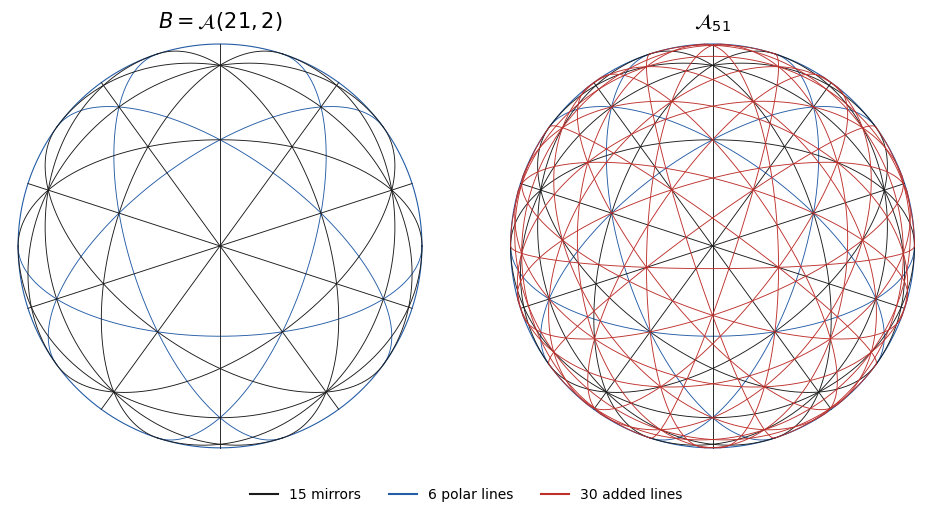

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

view = np.array([0.0, float(AA(phi)), 1.0])
view /= np.linalg.norm(view)
horizontal = np.array([1.0,0.0,0.0])
vertical = np.cross(view,horizontal)
angles = np.linspace(0.0,np.pi,700)

def draw_hemisphere(ax, orbits_to_draw):
    for normals,color in orbits_to_draw:
        for normal in normals:
            n = np.array([float(AA(a)) for a in normal])
            n /= np.linalg.norm(n)
            tangent = np.cross(n,view)
            if np.linalg.norm(tangent) < 1e-12:
                theta = np.linspace(0.0,2.0*np.pi,1000)
                ax.plot(np.cos(theta),np.sin(theta),color=color,lw=0.8)
                continue
            tangent /= np.linalg.norm(tangent)
            inward = np.cross(n,tangent)
            if np.dot(inward,view) < 0:
                inward = -inward
            circle = tangent[:,None]*np.cos(angles) + inward[:,None]*np.sin(angles)
            ax.plot(horizontal@circle,vertical@circle,color=color,lw=0.65)
    ax.set_aspect("equal")
    ax.set_xlim(-1.04,1.04)
    ax.set_ylim(-1.04,1.04)
    ax.axis("off")

fig,axes = plt.subplots(1,2,figsize=(10,5))
draw_hemisphere(axes[0],[(O6,"#245ca6"),(O15,"#1b1b1b")])
draw_hemisphere(axes[1],[(O6,"#245ca6"),(O15,"#1b1b1b"),(O30,"#bd302c")])
axes[0].set_title(r"$B=\mathcal{A}(21,2)$",fontsize=15)
axes[1].set_title(r"$\mathcal{A}_{51}$",fontsize=15)
fig.legend(handles=[
    Line2D([0],[0],color="#1b1b1b",label="15 mirrors"),
    Line2D([0],[0],color="#245ca6",label="6 polar lines"),
    Line2D([0],[0],color="#bd302c",label="30 added lines"),
],loc="lower center",ncol=3,frameon=False)
fig.tight_layout(rect=(0,0.08,1,1))
plt.show()

## 15. Verification result

The computations certify the finite construction and the hypotheses used in the paper's conclusions. The classification facts about near-pencils, the two infinite families, and characteristic polynomials of supersolvable arrangements are the mathematical implications stated in the paper; they are not assumptions that the catalogue is complete. The cross-ratio obstruction applies to this projective realization.

In [21]:
print("ALL CHECKS PASSED")
print("SageMath:", SAGE_VERSION, "| exact field: Q(s), s^4-s^2-1=0, s>0")
print("51 lines; 361 vertices; 1080 edges; 720 projective triangular chambers.")
print("Native Sage/Normaliz enumeration: 1440 simplicial central chambers.")
print("All twelve point orbits, both concurrence identities, pencil, and cross-ratio verified.")
print("Both classical catalogue identifications and the repository certificate verified.")
print("Irreducible, sporadic, and not supersolvable.")
print("Successful exact checks:", len(checks))

ALL CHECKS PASSED
SageMath: 10.8 | exact field: Q(s), s^4-s^2-1=0, s>0
51 lines; 361 vertices; 1080 edges; 720 projective triangular chambers.
Native Sage/Normaliz enumeration: 1440 simplicial central chambers.
All twelve point orbits, both concurrence identities, pencil, and cross-ratio verified.
Both classical catalogue identifications and the repository certificate verified.
Irreducible, sporadic, and not supersolvable.
Successful exact checks: 3071
